[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/19_neural_networks.ipynb)

# 19 · Neural Networks: Stacking Simple Units Into Flexible Functions

**Part 3 — Deep learning** · Notebook 19 of 27

Every model so far came with its shape fixed in advance: a line, a set of axis-aligned boxes, a mixture of Gaussians, a low-rank matrix. When the shape was wrong, we engineered features by hand (polynomials in notebook 05, kernels in notebook 11) to bend the problem into something the model could handle.

A neural network **learns its own features**. It's a stack of very simple units, each one a logistic regression, where the outputs of one layer become the inputs to the next. With enough units, such a stack can approximate essentially any function, and gradient descent with backpropagation (notebook 04) tunes all of it at once. This notebook builds that idea up from the 1958 perceptron to a multi-layer network written from scratch in NumPy, and looks closely at what the hidden layers actually do.

**What you'll learn**

1. Why linear models fail, starting with XOR
2. The perceptron: a neuron, logic gates, and the perceptron learning rule
3. Stacking perceptrons solves XOR
4. Activation functions, and why we need smooth ones
5. Universal approximation: how sums of simple units can draw any curve
6. A multi-layer network from scratch: forward pass, backprop, gradient check
7. Watching a network learn a decision boundary
8. What hidden layers do: they bend space (and what width-2 layers *can't* do)
9. Handwritten digits, and what the hidden units look for
10. Training pitfalls: initialization, vanishing gradients, overfitting
11. The architecture zoo, and why deep learning works at scale

*Course map: ISYE 4600 W10 (Neural Networks: nonlinear boundaries, XOR, the perceptron, NAND/XOR examples, expressive power, logistic regression as a neuron, activation functions, multilayer networks, backpropagation, digit and wine examples, CNN/RNN/ResNet/GAN/autoencoder overview) and HW4 Q3 (backprop gradients for a two-layer sigmoid network); CX 4240 lecture 11 (neural networks and backpropagation, MLP as the "Gaussian/Bernoulli/categorical + neural network" pipeline).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from sklearn.datasets import make_moons, make_circles, load_digits, load_wine
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
print("Ready ✓")

Setup complete ✓


Ready ✓


---
## 1. Why linear models fail: XOR

ISYE W10 starts with the **XOR gate**: output 1 when exactly one input is 1.

| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

The 1s sit on one diagonal of the square and the 0s on the other. No single straight line puts both 1s on one side and both 0s on the other. Logistic regression, a linear SVM, linear discriminant analysis, a single perceptron: all draw one line, so all fail. Here's logistic regression trying anyway, on a noisy version of XOR:

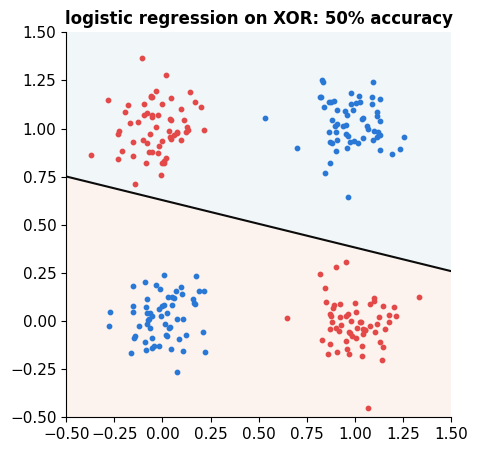

In [2]:
r_ = np.random.default_rng(0)
corners = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]); xor_y = np.array([0, 1, 1, 0])
Xx = np.repeat(corners, 60, axis=0) + r_.normal(0, 0.12, (240, 2)); yx = np.repeat(xor_y, 60)
lr_xor = LogisticRegression().fit(Xx, yx)
gx, gy = np.meshgrid(np.linspace(-0.5, 1.5, 300), np.linspace(-0.5, 1.5, 300)); Gx = np.column_stack([gx.ravel(), gy.ravel()])

def show_boundary(ax, prob_fn, X, y, title, grid=(gx, gy)):
    P = prob_fn(np.column_stack([grid[0].ravel(), grid[1].ravel()])).reshape(grid[0].shape)
    ax.contourf(grid[0], grid[1], P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.5)
    ax.contour(grid[0], grid[1], P, levels=[0.5], colors=[C["ink"]], linewidths=1.5)
    ax.scatter(*X[y == 0].T, s=10, color=C["blue"]); ax.scatter(*X[y == 1].T, s=10, color=C["red"])
    ax.set(aspect="equal", title=title); ax.grid(False)

fig, ax = plt.subplots(figsize=(5.5, 5))
show_boundary(ax, lambda G: lr_xor.predict_proba(G)[:, 1], Xx, yx, f"logistic regression on XOR: {lr_xor.score(Xx, yx):.0%} accuracy")
plt.show()

About coin-flip accuracy. The only linear fix is to hand-craft a feature like $x_1x_2$ (with it, XOR becomes linearly separable). A neural network will discover such features itself.

> 🤔 **Question: Which classifiers from earlier notebooks *do* handle XOR?** (ISYE W10)
>
> Anything nonlinear: KNN (notebook 10) looks at nearby points, so it's fine; a depth-2 decision tree (notebook 12) splits on $x_1$ then $x_2$; an RBF-kernel SVM (notebook 11) lifts the points to a space where a plane separates them; a GMM classifier with one component per corner works too. Neural networks belong to the same family but **learn** the transformation instead of fixing it in advance (KNN's distance, the tree's axis-aligned splits, the SVM's kernel).

---
## 2. The perceptron

The **perceptron** (Rosenblatt, 1958) is the original artificial neuron. ISYE's mapping from biology: inputs arrive on **dendrites**, each with a **synaptic strength** (weight); the cell body sums them; if the total passes a **firing threshold**, the neuron fires.

$$y = \mathbb{I}\big(w_1x_1 + w_2x_2 + \dots + w_nx_n > \theta\big).$$

Rosenblatt's Mark I Perceptron was a machine: a 20 × 20 grid of photocells wired to "neurons", with weights stored in motor-driven potentiometers.

### Logic gates from one neuron

With the right weights, one perceptron can compute AND, OR, or NAND. ISYE's slide lists weight pairs with threshold θ = 0.5, such as (0.20, 0.35) and (0.40, 0.20). Let's check what they compute:

In [3]:
def perceptron(X, w, theta): return (X @ np.asarray(w) > theta).astype(int)

for w in [(0.20, 0.35), (0.20, 0.40), (0.25, 0.30), (0.40, 0.20)]:
    print(f"w = {w}, θ = 0.5  →  outputs on (0,0),(0,1),(1,0),(1,1): {perceptron(corners, w, 0.5)}")
print("\nNAND needs negative weights and a negative threshold, e.g. w = (-0.5, -0.5), θ = -0.75:", perceptron(corners, (-0.5, -0.5), -0.75))

w = (0.2, 0.35), θ = 0.5  →  outputs on (0,0),(0,1),(1,0),(1,1): [0 0 0 1]
w = (0.2, 0.4), θ = 0.5  →  outputs on (0,0),(0,1),(1,0),(1,1): [0 0 0 1]
w = (0.25, 0.3), θ = 0.5  →  outputs on (0,0),(0,1),(1,0),(1,1): [0 0 0 1]
w = (0.4, 0.2), θ = 0.5  →  outputs on (0,0),(0,1),(1,0),(1,1): [0 0 0 1]

NAND needs negative weights and a negative threshold, e.g. w = (-0.5, -0.5), θ = -0.75: [1 1 1 0]


The listed weights give outputs 0, 0, 0, 1: that's **AND** (fire only when both inputs are on), which matches the truth table drawn on that slide. **NAND** ("not both") is AND's complement: flip the signs of the weights and the threshold. NAND matters because it's *universal*: every Boolean circuit can be built from NAND gates alone. So networks of perceptrons can compute any Boolean function.

### The perceptron learning rule

Rosenblatt's real contribution was a way to **learn** the weights from examples. Fold the threshold into a bias ($w_0 = -\theta$, with a constant input $x_0 = 1$), use labels $y \in \{-1, +1\}$, and repeat:

> For each training point, if it's misclassified ($y\,w^\top x \le 0$), update $w \leftarrow w + y\,x$.

A misclassified positive point gets added to $w$, which rotates the boundary toward classifying it correctly, and vice versa. This is SGD on the loss $\max(0, -y\,w^\top x)$, a hinge loss with no margin (notebook 11). **The perceptron convergence theorem** (Novikoff, 1962): if the data are linearly separable with margin $\gamma$ and all points lie within radius $R$, the algorithm makes at most $(R/\gamma)^2$ mistakes, then stops.

In [4]:
r_ = np.random.default_rng(3)
Xp = r_.normal(0, 1, (60, 2)); w_true = np.array([1.0, -0.6]); keep = np.abs(Xp @ w_true + 0.3) > 0.25
Xp = Xp[keep]; yp = np.sign(Xp @ w_true + 0.3)
Xp1 = np.c_[np.ones(len(Xp)), Xp]                              # constant input for the bias
w = np.zeros(3); hist = [w.copy()]; mistakes = []
for epoch in range(20):
    errs = 0
    for xi, yi in zip(Xp1, yp):
        if yi * (w @ xi) <= 0:
            w = w + yi * xi; hist.append(w.copy()); mistakes.append(xi); errs += 1
    if errs == 0: break
print(f"converged after {len(hist) - 1} updates, in {epoch + 1} passes over the data")

fig, ax = plt.subplots(figsize=(6, 5.5))
xs = np.linspace(-3, 3, 10)
def frame_p(t):
    ax.clear()
    ax.scatter(*Xp[yp < 0].T, color=C["blue"], s=25); ax.scatter(*Xp[yp > 0].T, color=C["red"], s=25)
    wt = hist[t]
    if np.abs(wt[2]) > 1e-9: ax.plot(xs, -(wt[0] + wt[1] * xs) / wt[2], color=C["ink"], lw=2)
    if t > 0: ax.scatter(*mistakes[t - 1][1:], s=200, facecolors="none", edgecolors=C["orange"], lw=2.5)
    ax.set(xlim=(-3, 3), ylim=(-3, 3), aspect="equal", title=f"update {t}: w = {np.round(wt, 2)}\n(orange ring = the misclassified point that caused it)")
anim = animation.FuncAnimation(fig, frame_p, frames=len(hist), interval=600)
show_anim(anim)

converged after 5 updates, in 3 passes over the data


Each update is triggered by one misclassified point (orange ring) and swings the line toward fixing it. After a handful of updates every point is on the right side, and the algorithm stops.

On XOR the algorithm never stops: there's no separating line, so some point is always misclassified and the weights cycle forever. Minsky and Papert's 1969 book *Perceptrons* made this limitation famous, and it contributed to the first "AI winter". The fix, already known in principle, was to **stack** perceptrons.

---
## 3. Stacking perceptrons solves XOR

A hidden layer of two perceptrons computes intermediate features; an output perceptron combines them. ISYE's slide gives one set of weights, with θ = 0.5 for every unit: $(w_1, \dots, w_6) = (0.6, -0.6, -0.7, 0.8, 1, 1)$.

- Hidden unit 1: fires when $0.6x_1 - 0.6x_2 > 0.5$, i.e. "$x_1$ and not $x_2$".
- Hidden unit 2: fires when $-0.7x_1 + 0.8x_2 > 0.5$, i.e. "$x_2$ and not $x_1$".
- Output: fires when $h_1 + h_2 > 0.5$, i.e. "either hidden unit".

 x1  x2  h1 (x1 and not x2)  h2 (x2 and not x1)  output  XOR
  0   0                   0                   0       0    0
  0   1                   0                   1       1    1
  1   0                   1                   0       1    1
  1   1                   0                   0       0    0


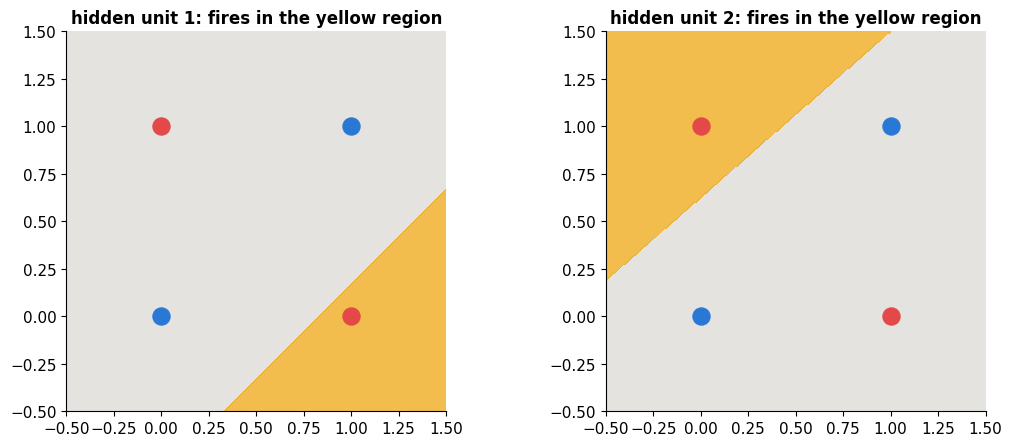

In [5]:
H = np.column_stack([perceptron(corners, (0.6, -0.6), 0.5), perceptron(corners, (-0.7, 0.8), 0.5)])
out = perceptron(H, (1, 1), 0.5)
print(pd.DataFrame({"x1": corners[:, 0], "x2": corners[:, 1], "h1 (x1 and not x2)": H[:, 0], "h2 (x2 and not x1)": H[:, 1], "output": out, "XOR": xor_y}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (w, nm) in zip(axes, [((0.6, -0.6), "hidden unit 1"), ((-0.7, 0.8), "hidden unit 2")]):
    ax.contourf(gx, gy, perceptron(Gx, w, 0.5).reshape(gx.shape), levels=[-0.5, 0.5, 1.5], colors=[C["light"], C["yellow"]], alpha=0.7)
    ax.scatter(*corners[xor_y == 0].T, s=150, color=C["blue"]); ax.scatter(*corners[xor_y == 1].T, s=150, color=C["red"])
    ax.set(aspect="equal", title=f"{nm}: fires in the yellow region"); ax.grid(False)
fig.tight_layout(); plt.show()

Each hidden unit draws one line, cutting off one of the red corners. The output unit ORs them. Two lines plus a combination: a nonlinear boundary out of linear pieces. That's the whole idea of a multi-layer network, and **hidden layers are feature detectors** whose features nobody had to specify. Here we set the weights by hand; the rest of the notebook is about learning them.

---
## 4. Activation functions

The perceptron's step function has a fatal flaw for learning: its derivative is zero everywhere (except at the jump, where it's undefined). Gradient descent gets no signal. So modern networks replace the step with a smooth or piecewise-linear **activation function** $\phi$. A unit computes $\phi(w^\top x + b)$; with $\phi = \sigma$ (the sigmoid), a single unit **is** logistic regression (ISYE W10: *"neural nets generalize logistic regression by stacking multiple sigmoid units"*).

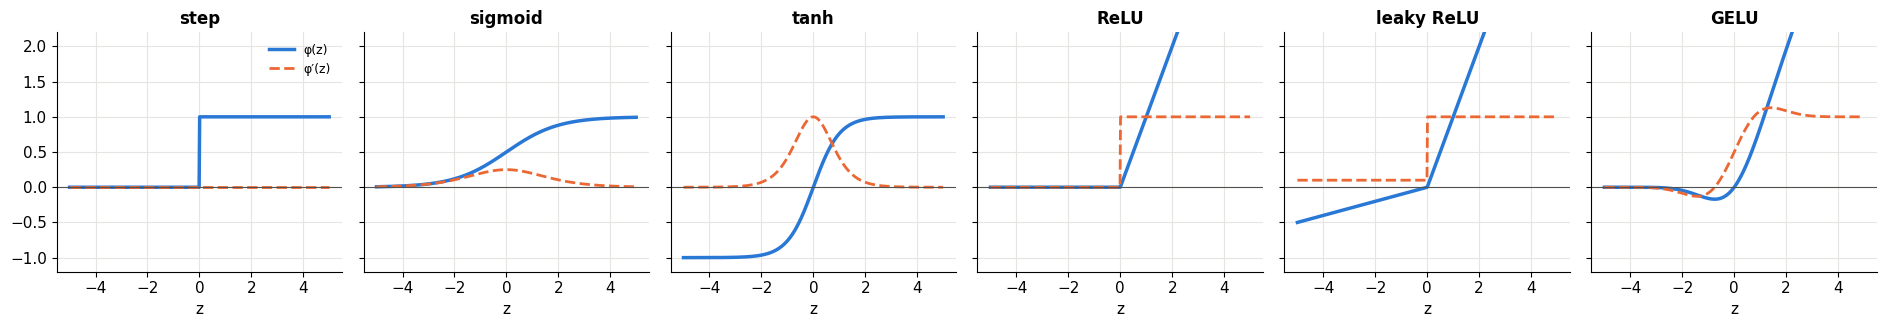

In [6]:
z = np.linspace(-5, 5, 500)
sig = lambda z: 1 / (1 + np.exp(-z))
acts = {
    "step":       (lambda z: (z > 0).astype(float),      lambda z: np.zeros_like(z)),
    "sigmoid":    (sig,                                  lambda z: sig(z) * (1 - sig(z))),
    "tanh":       (np.tanh,                              lambda z: 1 - np.tanh(z) ** 2),
    "ReLU":       (lambda z: np.maximum(z, 0),           lambda z: (z > 0).astype(float)),
    "leaky ReLU": (lambda z: np.where(z > 0, z, 0.1 * z), lambda z: np.where(z > 0, 1, 0.1)),
    "GELU":       (lambda z: 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z ** 3))), None),   # derivative taken numerically below
}
fig, axes = plt.subplots(1, 6, figsize=(19, 3.4), sharey=True)
for ax, (nm, (f, df)) in zip(axes, acts.items()):
    ax.plot(z, f(z), color=C["blue"], lw=2.5, label="φ(z)")
    d = df(z) if df is not None else np.gradient(f(z), z)
    ax.plot(z, d, color=C["orange"], lw=2, ls="--", label="φ′(z)")
    ax.axhline(0, color=C["muted"], lw=0.8); ax.set(title=nm, ylim=(-1.2, 2.2), xlabel="z")
axes[0].legend(fontsize=9)
fig.tight_layout(); plt.show()

| Activation | Pros | Cons |
|---|---|---|
| step | the original; exact thresholds | zero gradient: can't be trained by gradient descent |
| sigmoid | outputs in (0, 1), a probability | gradient ≤ 0.25 and tiny for large $|z|$ → vanishing gradients in deep nets; not zero-centered |
| tanh | zero-centered, outputs in (−1, 1) | still saturates at both ends |
| **ReLU** | trivially cheap, gradient exactly 1 when active, sparse activations | gradient 0 for $z < 0$: a unit stuck there never recovers ("dead ReLU") |
| leaky ReLU | small slope keeps dead units alive | an extra hyperparameter |
| GELU | smooth ReLU; the default in transformers (notebook 25) | slightly more compute |

Sigmoid and tanh dominated until about 2010; ReLU made training deep networks much easier (section 10 shows why).

> 🤔 **Question: Why do we need a nonlinearity at all? Couldn't we just stack linear layers?**
>
> A stack of linear layers is still linear: $W_2(W_1x + b_1) + b_2 = (W_2W_1)x + (W_2b_1 + b_2)$, which is a single linear layer with weight $W_2W_1$. No matter how many you stack, you get one line (or plane). The nonlinearity between layers is what lets depth create new shapes. (A linear network with a narrow middle layer does still compute something interesting: it ends up doing PCA, notebook 16.)

---
## 5. Universal approximation

ISYE W10: *"Every bounded continuous function can be approximated with arbitrarily small error by a network with one hidden layer."* That's the **universal approximation theorem** (Cybenko 1989; Hornik 1991). The intuition is constructive. A sigmoid with a large weight is nearly a step. Two steps, one up and one down, make a **bump**. Enough bumps, scaled to the right heights, trace out any curve, like a histogram drawn with smooth bars.

🎚️ **Change the number of hidden units** (each pair of sigmoids makes one bump) and the steepness:

In [7]:
target = lambda x: np.sin(2 * x) + 0.5 * np.cos(5 * x) + 0.3 * x
xs1 = np.linspace(-3, 3, 800)
def approx_demo(n_bumps=6, steepness=10.0):
    edges = np.linspace(-3, 3, n_bumps + 1); centers = (edges[:-1] + edges[1:]) / 2; heights = target(centers)
    f = np.zeros_like(xs1); fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    for a, b_, h in zip(edges[:-1], edges[1:], heights):
        bump = h * (sig(steepness * (xs1 - a)) - sig(steepness * (xs1 - b_)))   # two hidden sigmoid units
        f += bump; axes[0].plot(xs1, bump, lw=1)
    axes[0].set(title=f"{n_bumps} bumps = {2 * n_bumps} sigmoid hidden units, each bump: h·[σ(s(x−a)) − σ(s(x−b))]")
    axes[1].plot(xs1, target(xs1), color=C["ink"], lw=3, label="target function")
    axes[1].plot(xs1, f, color=C["red"], lw=2, label=f"network output (max error {np.abs(f - target(xs1)).max():.2f})")
    axes[1].set(title="sum of the bumps"); axes[1].legend(fontsize=9)
    for ax in axes: ax.set(xlabel="x"); ax.title.set_fontsize(10)
    fig.tight_layout(); plt.show()

interact(approx_demo, n_bumps=IntSlider(value=6, min=1, max=60, description="bumps"), steepness=FloatSlider(value=10, min=1, max=100, step=1, description="steepness"));

More bumps, smaller error, without limit: that's the theorem. But read the fine print:

- It says a good network **exists**, not that gradient descent will **find** it.
- The number of units can be enormous. ISYE notes the Boolean version may need exponentially many hidden units.
- It says nothing about **generalization**: memorizing the training points is also "approximation".

Why use **deep** networks, then, if one wide layer suffices? Because depth can be exponentially more efficient for functions with compositional structure. A function made by composing simple pieces (edges → shapes → objects in an image) can be represented compactly by stacking layers, while a single layer may need vastly more units to fake it. ISYE: *"Depth trades off number of units vs. compositional structure."*

---
## 6. A multi-layer network from scratch

Now the real thing. A **multi-layer perceptron** (MLP) with $L$ layers computes

$$a^{(0)} = x, \qquad z^{(\ell)} = W^{(\ell)}a^{(\ell-1)} + b^{(\ell)}, \qquad a^{(\ell)} = \phi(z^{(\ell)}) \;\;(\ell < L), \qquad \hat p = \mathrm{softmax}(z^{(L)}).$$

The last layer depends on the task (ISYE W10; CX lecture 11): **softmax with cross-entropy** for classification (notebook 08), a **linear output with squared error** for regression. That's CX 4240's pipeline with "linear model" replaced by "neural network": the probabilistic model and the loss are the same; only the function inside changed.

**Backpropagation** (notebook 04) computes all the gradients in one backward sweep. With softmax + cross-entropy, the output error is simply $\delta^{(L)} = \hat p - y_{\text{one-hot}}$ (notebook 08). Then, layer by layer going backward,

$$\frac{\partial \mathcal{L}}{\partial W^{(\ell)}} = \delta^{(\ell)}a^{(\ell-1)\top}, \qquad \frac{\partial \mathcal{L}}{\partial b^{(\ell)}} = \delta^{(\ell)}, \qquad \delta^{(\ell-1)} = \big(W^{(\ell)\top}\delta^{(\ell)}\big)\odot\phi'(z^{(\ell-1)}).$$

Each layer's error is the next layer's error, sent back through the weights and scaled by the local slope of the activation: ISYE's *"hidden-layer gradients reuse downstream errors"*. Here it is for a whole batch at once (rows are examples):

In [8]:
class MLP:
    """A fully connected network with tanh/ReLU hidden layers and a softmax output, in plain NumPy."""
    def __init__(self, sizes, activation="tanh", seed=0, init="auto"):
        r = np.random.default_rng(seed); self.act = activation; self.W, self.b = [], []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            scale = {"auto": np.sqrt((2.0 if activation == "relu" else 1.0) / n_in), "small": 0.01, "large": 1.0}[init] if isinstance(init, str) else init
            self.W.append(r.normal(0, scale, (n_in, n_out))); self.b.append(np.zeros(n_out))
    def phi(self, z):  return np.tanh(z) if self.act == "tanh" else np.maximum(z, 0) if self.act == "relu" else sig(z)
    def dphi(self, z, a): return 1 - a ** 2 if self.act == "tanh" else (z > 0).astype(float) if self.act == "relu" else a * (1 - a)
    def forward(self, X):
        self.zs, self.as_ = [], [X]
        for l, (W, b) in enumerate(zip(self.W, self.b)):
            z = self.as_[-1] @ W + b; self.zs.append(z)
            if l < len(self.W) - 1: self.as_.append(self.phi(z))
        z = z - z.max(1, keepdims=True); e = np.exp(z); self.p = e / e.sum(1, keepdims=True)   # stable softmax
        return self.p
    def loss(self, X, y, l2=0.0):
        p = self.forward(X); return -np.log(p[np.arange(len(y)), y] + 1e-12).mean() + 0.5 * l2 * sum((W ** 2).sum() for W in self.W)
    def backward(self, y, l2=0.0):
        m = len(y); delta = self.p.copy(); delta[np.arange(m), y] -= 1; delta /= m        # δ at the output: p − onehot
        gW, gb = [None] * len(self.W), [None] * len(self.W)
        for l in range(len(self.W) - 1, -1, -1):
            gW[l] = self.as_[l].T @ delta + l2 * self.W[l]; gb[l] = delta.sum(0)
            if l > 0: delta = (delta @ self.W[l].T) * self.dphi(self.zs[l - 1], self.as_[l])   # send the error back one layer
        return gW, gb
    def predict(self, X): return self.forward(X).argmax(1)

Before trusting it, **check the gradients** against finite differences (notebook 04's habit): nudge one weight by $\pm\varepsilon$ and see how the loss changes.

In [9]:
r_ = np.random.default_rng(1)
Xc_, yc_ = r_.normal(size=(20, 3)), r_.integers(0, 3, 20)
net = MLP([3, 5, 4, 3], activation="tanh", seed=2)
net.loss(Xc_, yc_, l2=0.01); gW, gb = net.backward(yc_, l2=0.01)
eps, worst = 1e-6, 0.0
for l in range(3):
    for idx in [(0, 0), (1, 2), (2, 1)]:
        if idx[0] >= net.W[l].shape[0] or idx[1] >= net.W[l].shape[1]: continue
        old = net.W[l][idx]
        net.W[l][idx] = old + eps; lp = net.loss(Xc_, yc_, l2=0.01)
        net.W[l][idx] = old - eps; lm = net.loss(Xc_, yc_, l2=0.01); net.W[l][idx] = old
        num = (lp - lm) / (2 * eps); worst = max(worst, abs(num - gW[l][idx]) / max(1e-8, abs(num) + abs(gW[l][idx])))
print(f"largest relative difference between backprop and finite differences: {worst:.2e}  (≈1e-7 or smaller means correct)")

largest relative difference between backprop and finite differences: 2.80e-08  (≈1e-7 or smaller means correct)


Backprop agrees with brute-force differentiation to many digits. (HW4 Q3 derives these gradients by hand for a small two-layer sigmoid network; notebook 04 worked through the same lecture example with an autograd engine.)

---
## 7. Watching a network learn

The **spiral** dataset (three intertwined arms, a favorite of Karpathy's CS231n) is hopeless for any linear classifier. Train a 2 → 64 → 64 → 3 ReLU network with plain gradient descent and watch the decision regions form:

In [10]:
def make_spiral(n_per=120, k=3, noise=0.25, seed=0):
    r = np.random.default_rng(seed); X, y = [], []
    for c in range(k):
        t = np.linspace(0.0, 1, n_per); ang = t * 4 + c * 2 * np.pi / k + r.normal(0, noise, n_per)
        X.append(np.column_stack([t * np.sin(ang), t * np.cos(ang)])); y.append(np.full(n_per, c))
    return np.vstack(X), np.concatenate(y)

Xs, ys = make_spiral()
net = MLP([2, 64, 64, 3], activation="relu", seed=0)
gs1, gs2 = np.meshgrid(np.linspace(-1.2, 1.2, 200), np.linspace(-1.2, 1.2, 200)); Gs = np.column_stack([gs1.ravel(), gs2.ravel()])
snaps, losses, lr = [], [], 0.5
for step in range(3001):
    L_ = net.loss(Xs, ys); gW, gb = net.backward(ys)
    for l in range(len(net.W)): net.W[l] -= lr * gW[l]; net.b[l] -= lr * gb[l]
    losses.append(L_)
    if step in (0, 3, 6, 10, 15, 20, 30, 40, 55, 70, 90, 120, 160, 250, 500, 3000):
        snaps.append((step, net.predict(Gs).reshape(gs1.shape), (net.predict(Xs) == ys).mean()))
print(f"final training accuracy: {(net.predict(Xs) == ys).mean():.1%}")

lin = LogisticRegression().fit(Xs, ys)
cmap3 = plt.matplotlib.colors.ListedColormap([C["blue"], C["orange"], C["aqua"]])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw=dict(width_ratios=[1.1, 1]))
def frame_s(t):
    ax.clear(); ax2.clear()
    step, Zs, acc = snaps[t]
    ax.contourf(gs1, gs2, Zs, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap3, alpha=0.3)
    ax.scatter(*Xs.T, c=ys, cmap=cmap3, s=12, edgecolor="k", linewidth=0.2)
    ax.set(aspect="equal", title=f"step {step}: training accuracy {acc:.0%}"); ax.grid(False)
    ax2.plot(losses[:step + 1], color=C["red"]); ax2.set(xlim=(0, 3000), ylim=(0, 1.2), xlabel="gradient step", ylabel="cross-entropy loss",
                                                         title=f"(logistic regression reaches {lin.score(Xs, ys):.0%})")
anim = animation.FuncAnimation(fig, frame_s, frames=len(snaps), interval=600)
show_anim(anim)

final training accuracy: 99.4%


At first the network splits the plane into crude wedges (roughly what a linear model can do). Within a few dozen steps the regions start to curl, and after about 150 steps they follow the spiral arms; the remaining steps only polish the boundary. Nobody told the network about spirals or polar coordinates: the hidden layers built the features needed to separate them.

---
## 8. What hidden layers do: they bend space

Each layer applies a linear map (rotate, stretch, shift) and then squashes each coordinate with the activation. Geometrically, that **bends** the space. A network classifies by bending the data until a straight line can separate the classes in the last hidden layer's coordinates. We can watch this directly with a network whose hidden layers have exactly 2 units, so every layer's representation can be drawn on a page (an idea from Chris Olah's essay *Neural Networks, Manifolds, and Topology*):

2-2-2-2 tanh network on the moons: training accuracy 100.0%


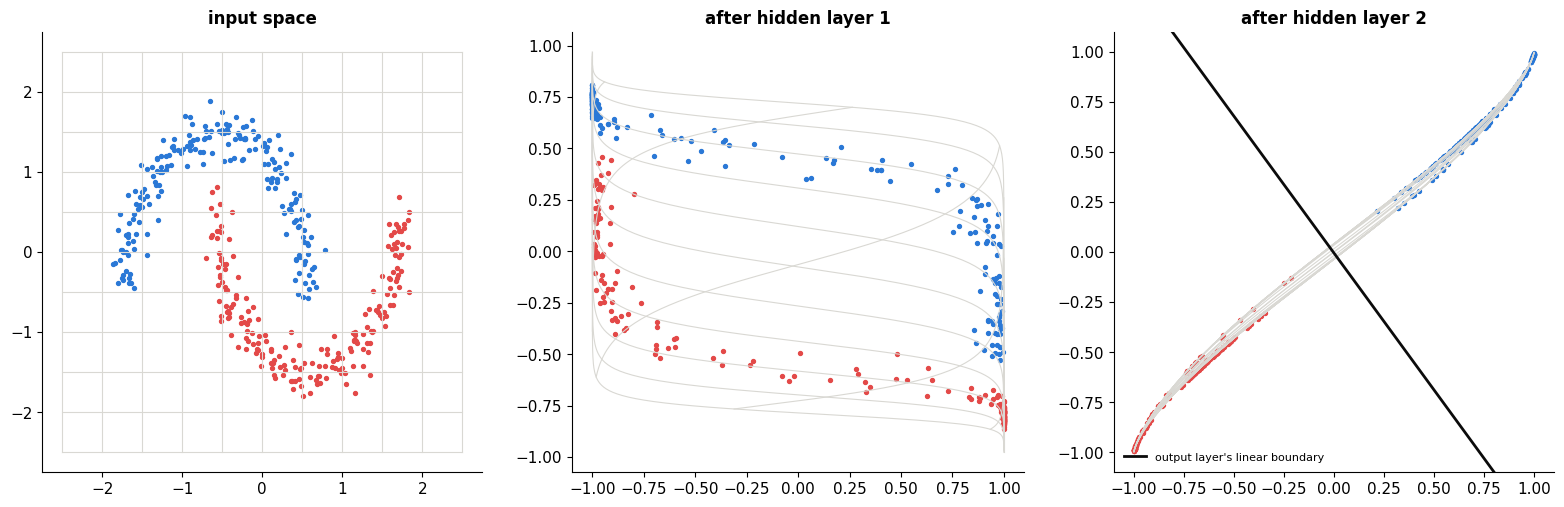

In [11]:
Xm, ym = make_moons(400, noise=0.08, random_state=0); Xm = (Xm - Xm.mean(0)) / Xm.std(0)
best = None
for seed in range(10):                                         # tiny networks are sensitive to the start: keep the best of a few
    n2 = MLP([2, 2, 2, 2], activation="tanh", seed=seed, init=1.0)
    for step in range(4000):
        n2.loss(Xm, ym); gW, gb = n2.backward(ym)
        for l in range(3): n2.W[l] -= 0.3 * gW[l]; n2.b[l] -= 0.3 * gb[l]
    acc = (n2.predict(Xm) == ym).mean()
    if best is None or acc > best[0]: best = (acc, n2)
acc2, n2 = best
print(f"2-2-2-2 tanh network on the moons: training accuracy {acc2:.1%}")

n2.forward(Xm)
lines = [np.column_stack([np.linspace(-2.5, 2.5, 200), np.full(200, c)]) for c in np.linspace(-2.5, 2.5, 11)] + \
        [np.column_stack([np.full(200, c), np.linspace(-2.5, 2.5, 200)]) for c in np.linspace(-2.5, 2.5, 11)]
def through(n, P, upto):
    a = P
    for l in range(upto): a = n.phi(a @ n.W[l] + n.b[l])
    return a
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for k, ax in enumerate(axes):
    for ln in lines: ax.plot(*through(n2, ln, k).T, color=C["light"], lw=0.8)
    A = through(n2, Xm, k)
    ax.scatter(*A[ym == 0].T, s=8, color=C["blue"]); ax.scatter(*A[ym == 1].T, s=8, color=C["red"])
    if k == 2:
        W3, b3 = n2.W[2], n2.b[2]; wv = W3[:, 1] - W3[:, 0]; bv = b3[1] - b3[0]   # where the two softmax logits tie
        t_ = np.linspace(-1.1, 1.1, 50)
        if abs(wv[1]) > 1e-9: ax.plot(t_, -(bv + wv[0] * t_) / wv[1], color=C["ink"], lw=2, label="output layer's linear boundary"); ax.legend(fontsize=8, loc="lower left")
        ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1))
    ax.set(title=["input space", "after hidden layer 1", "after hidden layer 2"][k], aspect="equal"); ax.grid(False)
fig.tight_layout(); plt.show()

The grey lines are a square grid in the input, carried through the layers. Each tanh layer folds and squashes the grid (tanh pins everything inside the square [−1, 1]²), and by the second hidden layer the two moons have been pulled apart so that a single straight line, the output layer, separates them.

### What a width-2 network can't do

There's a limit to bending. A layer with an invertible weight matrix and tanh is a **continuous, invertible** map of the plane: it can stretch and fold the sheet but never **cut** or **tear** it. Now take concentric circles: the red ring surrounds the blue disk. No continuous deformation of the plane can pull the disk out of the ring, so if every layer is 2 units wide, no amount of training gives a straight-line separation. Give the hidden layer a **third** dimension and the disk can simply be lifted out of the plane. 🎚️ **Change the hidden width:**

In [12]:
Xo, yo = make_circles(400, factor=0.45, noise=0.06, random_state=1)
width_results = {}
for width in [1, 2, 3, 4, 8]:
    best = None
    for seed in range(6):
        nw = MLP([2, width, width, 2], activation="tanh", seed=seed, init=1.0)
        for step in range(3000):
            nw.loss(Xo, yo); gW, gb = nw.backward(yo)
            for l in range(3): nw.W[l] -= 0.3 * gW[l]; nw.b[l] -= 0.3 * gb[l]
        acc = (nw.predict(Xo) == yo).mean()
        if best is None or acc > best[0]: best = (acc, nw)
    width_results[width] = best
print("best training accuracy by hidden width:", {w: f"{a:.0%}" for w, (a, _) in width_results.items()})
go1, go2 = np.meshgrid(np.linspace(-1.5, 1.5, 200), np.linspace(-1.5, 1.5, 200)); Go = np.column_stack([go1.ravel(), go2.ravel()])

def width_demo(width=2):
    acc, nw = width_results[width]
    fig, ax = plt.subplots(figsize=(6, 5.5))
    show_boundary(ax, lambda G: nw.forward(G)[:, 1], Xo, yo, f"hidden layers of width {width}: best training accuracy {acc:.0%}", grid=(go1, go2))
    plt.show()

widths_ = list(width_results)
interact(lambda step=1: width_demo(widths_[step]), step=IntSlider(value=1, min=0, max=len(widths_) - 1, description="width 1,2,3,4,8", readout=False));

best training accuracy by hidden width: {1: '66%', 2: '91%', 3: '100%', 4: '100%', 8: '100%'}


With width 2 the boundary can only pinch a channel through the data, and the best training accuracy stalls around 90% (width 1 manages only about two-thirds). From width 3 on, the network wraps a closed curve around the inner disk. Wider and deeper networks can carve the space far more freely, which is why practical networks are many units wide.

---
## 9. Handwritten digits, and what the hidden units look for

ISYE's practical example: a one-hidden-layer network on handwritten digits, where each hidden unit's incoming weights can be **drawn as an image**: the pattern of pixels that excites it. Here with scikit-learn's 8 × 8 digits and our from-scratch MLP, trained with **mini-batch SGD** (notebook 03):

MLP 64-32-10:      test accuracy 97.2%
logistic regression: test accuracy 97.0%


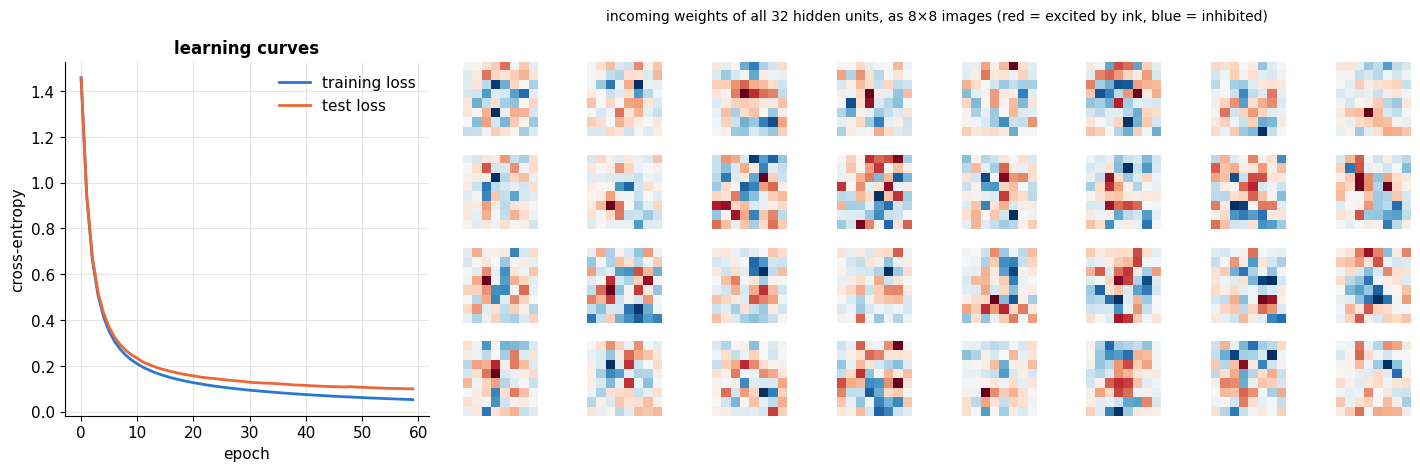

In [13]:
digits = load_digits(); Xd, yd = digits.data / 16.0, digits.target
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.3, random_state=0, stratify=yd)
mu_d = Xtr.mean(0); Xtr_c, Xte_c = Xtr - mu_d, Xte - mu_d

def train_sgd(net, X, y, Xv, yv, epochs=60, lr=0.1, batch=32, l2=0.0, seed=0):
    r = np.random.default_rng(seed); curve = []
    for ep in range(epochs):
        perm = r.permutation(len(X))
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]; net.loss(X[idx], y[idx], l2); gW, gb = net.backward(y[idx], l2)
            for l in range(len(net.W)): net.W[l] -= lr * gW[l]; net.b[l] -= lr * gb[l]
        curve.append((net.loss(X, y), (net.predict(X) == y).mean(), net.loss(Xv, yv), (net.predict(Xv) == yv).mean()))
    return np.array(curve)

dnet = MLP([64, 32, 10], activation="tanh", seed=0)
curve = train_sgd(dnet, Xtr_c, ytr, Xte_c, yte, epochs=60)
lr_d = LogisticRegression(max_iter=3000).fit(Xtr_c, ytr)
print(f"MLP 64-32-10:      test accuracy {curve[-1, 3]:.1%}")
print(f"logistic regression: test accuracy {lr_d.score(Xte_c, yte):.1%}")

fig = plt.figure(figsize=(16, 4.6))
ax = fig.add_subplot(1, 3, 1)
ax.plot(curve[:, 0], label="training loss"); ax.plot(curve[:, 2], label="test loss"); ax.set(xlabel="epoch", ylabel="cross-entropy", title="learning curves"); ax.legend()
gs_ = fig.add_gridspec(4, 16, left=0.36, right=0.98, wspace=0.1, hspace=0.25)
for k in range(32):
    a_ = fig.add_subplot(gs_[k // 8, (k % 8) * 2:(k % 8) * 2 + 2]); w_ = dnet.W[0][:, k].reshape(8, 8); v = np.abs(w_).max()
    a_.imshow(w_, cmap="RdBu_r", vmin=-v, vmax=v); a_.axis("off")
fig.text(0.67, 0.97, "incoming weights of all 32 hidden units, as 8×8 images (red = excited by ink, blue = inhibited)", ha="center", fontsize=10)
plt.show()

Here the network only ties logistic regression (a one-layer network on the raw pixels): these 8 × 8 digits are nearly linearly separable already, so there's little for hidden features to add. (On harder images the gap is large; notebooks 20 and 21 show it on clothing photos.) The hidden layer is still interesting to look at. Each hidden unit's weights form a stroke-like template: red where ink excites it, blue where ink inhibits it. Some look like pieces of loops, bars, or contrasts between the top and bottom of the digit. They're not digits themselves: they're **parts** that the output layer combines, the "feature detectors" from section 3, learned.

---
## 10. Training pitfalls

Unlike logistic regression, the loss of a neural network is **non-convex** (ISYE W10: *"Logistic regression → convex optimization; neural networks → non-convex optimization"*). Gradient descent finds a local optimum that depends on the start. In practice, for large networks, most local optima are about equally good; the bigger practical problems are these.

### Initialization and vanishing gradients

Backprop multiplies the error by $W^\top$ and by $\phi'(z)$ at every layer. If each step shrinks the signal, the gradients reaching the early layers become tiny and those layers stop learning (**vanishing gradients**); if each step grows it, they explode. The sigmoid is a culprit: $\sigma' \le 0.25$, so ten sigmoid layers can shrink a gradient by $0.25^{10} \approx 10^{-6}$. The cure has two parts: activations whose slope is 1 where active (ReLU), and **weight initialization** scaled to the layer width so that signals keep roughly the same size layer to layer (Glorot/Xavier: variance $1/n_{\text{in}}$ for tanh; He: $2/n_{\text{in}}$ for ReLU).

Let's measure the gradient size at each layer of a 12-layer network at initialization:

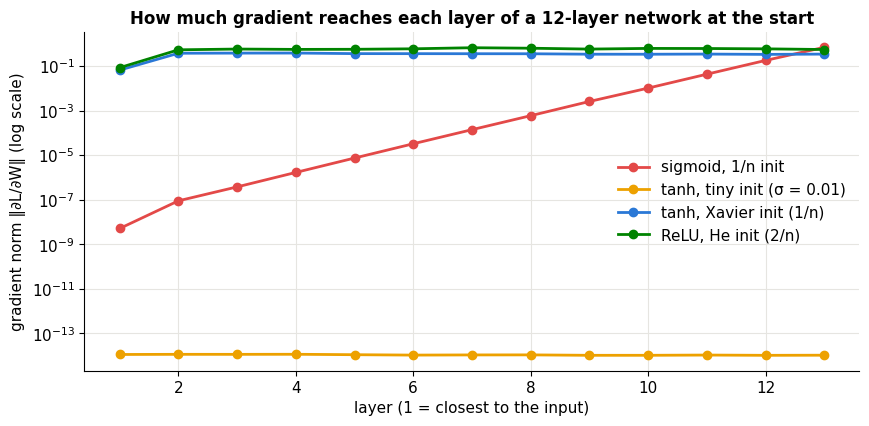

In [14]:
Xg, yg = make_spiral(100); depth, width = 12, 64
fig, ax = plt.subplots(figsize=(10, 4.4))
for (act, init, col, nm) in [("sigmoid", "auto", C["red"], "sigmoid, 1/n init"), ("tanh", "small", C["yellow"], "tanh, tiny init (σ = 0.01)"),
                              ("tanh", "auto", C["blue"], "tanh, Xavier init (1/n)"), ("relu", "auto", C["green"], "ReLU, He init (2/n)")]:
    norms = []
    for seed in range(5):
        n_ = MLP([2] + [width] * depth + [3], activation=act, seed=seed, init=init); n_.loss(Xg, yg); gW, _ = n_.backward(yg)
        norms.append([np.linalg.norm(g) for g in gW])
    ax.semilogy(range(1, depth + 2), np.mean(norms, 0), "o-", color=col, label=nm)
ax.set(xlabel="layer (1 = closest to the input)", ylabel="gradient norm ‖∂L/∂W‖ (log scale)", title="How much gradient reaches each layer of a 12-layer network at the start")
ax.legend(); plt.show()

With sigmoid units the gradient shrinks by about a factor of 4–5 per layer on its way back, so the first layer receives a hundred-millionth of what the last one gets and barely learns. With tiny initial weights the problem is even worse but different: the signal already dies in the **forward** pass (every layer multiplies it by small weights), so every layer's gradient is around $10^{-14}$ and nothing learns. With Xavier (tanh) or He (ReLU) initialization, the gradient stays roughly the same size through all twelve layers. Later fixes made very deep networks routine: **batch/layer normalization** (re-scaling activations inside the network, notebook 20) and **residual connections** ($x + f(x)$, which give gradients a shortcut; notebooks 21 and 25). LSTMs (notebook 22) solve the same problem for sequences.

### Overfitting and regularization

Networks have many parameters, so they can memorize small datasets (ISYE's wine example: *"risk of overfitting → need for regularization"*). The standard tools: **weight decay** (an L2 penalty on the weights, exactly ridge regression's penalty from notebook 07), **early stopping** (stop when validation loss starts rising), **dropout** (randomly silence units during training; notebook 20), and more data. 🎚️ **Change the weight decay** for a big network trained on only 60 noisy moon points:

In [15]:
Xsm, ysm = make_moons(60, noise=0.3, random_state=3); Xbig, ybig = make_moons(3000, noise=0.3, random_state=4)
reg_runs = {}
for l2 in [0.0, 0.001, 0.003, 0.01, 0.03, 0.1]:
    nr = MLP([2, 200, 200, 2], activation="relu", seed=0)
    cr = train_sgd(nr, Xsm, ysm, Xbig, ybig, epochs=3000, lr=0.2, batch=60, l2=l2)
    reg_runs[l2] = (nr, cr)
print(pd.DataFrame({l2: {"train acc": cr[-1, 1], "test acc": cr[-1, 3], "final test loss": cr[-1, 2]} for l2, (_, cr) in reg_runs.items()}).round(3).to_string())
gm1, gm2 = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.6, 2.1, 200))

def reg_demo(l2=0.0):
    nr, cr = reg_runs[l2]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
    show_boundary(axes[0], lambda G: nr.forward(G)[:, 1], Xsm, ysm, f"weight decay λ = {l2}: train {cr[-1, 1]:.0%}, test {cr[-1, 3]:.0%}", grid=(gm1, gm2))
    axes[1].plot(cr[:, 0], label="training loss"); axes[1].plot(cr[:, 2], label="test loss (3,000 fresh points)")
    axes[1].axvline(cr[:, 2].argmin(), color=C["muted"], ls=":", label=f"early stopping point (epoch {cr[:, 2].argmin()})")
    axes[1].set(ylim=(0, 1.5), xlabel="epoch", ylabel="cross-entropy", title="train vs. test loss"); axes[1].legend(fontsize=9)
    fig.tight_layout(); plt.show()

l2s_ = list(reg_runs)
interact(lambda step=0: reg_demo(l2s_[step]), step=IntSlider(value=0, min=0, max=len(l2s_) - 1, description="λ step", readout=False));

                 0.000  0.001  0.003  0.010  0.030  0.100
train acc        1.000  1.000  0.983  0.917  0.867  0.833
test acc         0.844  0.856  0.866  0.870  0.851  0.830
final test loss  1.223  0.690  0.375  0.289  0.347  0.387


Without weight decay, the 40,000-parameter network draws a contorted boundary around individual noisy points: 100% training accuracy, while the test loss reaches its minimum within the first few dozen epochs and then more than triples as the network grows ever more confident about its memorized points (the dotted line marks where early stopping would have stopped). Moderate weight decay (λ ≈ 0.01) keeps the weights small, which keeps the function smooth: training accuracy drops to about 92%, but test accuracy rises and the test loss is the lowest in the table. Too much (λ = 0.1) and the boundary flattens toward a line (underfitting). It's the bias–variance trade-off from notebook 06, with λ as the dial.

---
## 11. The architecture zoo, and why deep learning works at scale

Fully connected layers treat every input as unrelated to every other. Most data has structure, and the most successful architectures build that structure in (ISYE W10):

| Architecture | Built-in assumption | Typical data | Notebook |
|---|---|---|---|
| **Fully connected (MLP)** | none | tabular, small inputs | this one |
| **Convolutional (CNN)** | nearby pixels matter together; a pattern means the same thing anywhere in the image | images, audio | 21 |
| **Recurrent (RNN, LSTM)** | data comes in order; the same rule applies at every step | text, time series | 22 |
| **Residual network (ResNet)** | layers learn corrections $x + f(x)$, allowing 100+ layers | images (very deep) | 21 |
| **Autoencoder / VAE** | data can be compressed through a bottleneck and rebuilt | unlabeled data, generation | 23 |
| **GAN** | a generator and a discriminator trained against each other | image generation | 23 (mention) |
| **Transformer** | every element can attend to every other | text, now nearly everything | 25 |

**Why deep learning took off around 2012** (ISYE W10):

- **Representation learning.** Deep networks learn features from raw data (edges → textures → parts → objects) instead of relying on hand-engineered ones. The 2012 ImageNet result (AlexNet, 8 layers, 60 million parameters) beat the hand-engineered competition by more than 10 points of top-5 error.
- **Scale.** Performance keeps improving with more data and bigger models, long after classical methods plateau.
- **Hardware.** Training is dominated by large matrix multiplications, which GPUs do in parallel.
- **Better recipes.** ReLU, good initialization, dropout, batch normalization, Adam, residual connections.

**Limitations worth remembering:** networks need a lot of data and compute; they're hard to interpret; they can be confidently wrong on inputs unlike their training data (notebook 18's OOD problem); and on small tabular datasets, gradient-boosted trees (notebook 13) are still often better.

---
## 12. Summary

- A **neuron** computes $\phi(w^\top x + b)$. With a step function it's Rosenblatt's perceptron; with a sigmoid, it's logistic regression.
- One neuron draws one line. **Stacking** them, with a nonlinearity in between, builds features that make nonlinear problems linearly separable (XOR, moons, spirals).
- **Universal approximation:** one wide hidden layer can approximate any continuous function, but depth represents compositional functions far more efficiently, and existence isn't learnability.
- **Training** = choose a loss from a probabilistic model (cross-entropy for classification), compute gradients with **backpropagation**, descend with (mini-batch) **SGD**. Check gradients numerically when building from scratch.
- **Hidden layers bend space**; width limits what bends are possible.
- **Pitfalls:** non-convexity, vanishing/exploding gradients (fix: ReLU, Xavier/He initialization, normalization, residuals), and overfitting (fix: weight decay, early stopping, dropout, data).

Next, notebook 20 rebuilds all of this in **PyTorch**, where autograd computes the backward pass for us and the same training loop scales to GPUs and millions of parameters.

### ✏️ Exercises

1. Find weights and a threshold for a single perceptron that computes OR, and prove that no single perceptron computes XOR (hint: write the four inequalities and add them up in pairs).
2. Run the perceptron learning rule on the XOR corners and record $w$ after every epoch. Show that it cycles.
3. HW4 Q3: for $\ell = \sum_i(y^i - \sigma(w^\top z^i))^2$ with $z_1^i = \sigma(\alpha^\top x^i)$, $z_2^i = \sigma(\beta^\top x^i)$, derive $\partial\ell/\partial w$, $\partial\ell/\partial\alpha$, $\partial\ell/\partial\beta$. Implement them and check against finite differences.
4. Modify `MLP` to support a **regression** output (identity output, squared-error loss) and fit the target function of section 5 with 1, 5, and 50 tanh hidden units. Compare with the hand-built bumps.
5. Train the 12-layer sigmoid network from section 10 on the spiral for 2,000 steps, recording the gradient norm of the first and last layers. How long until the first layer's weights change noticeably?
6. Add **momentum** to `train_sgd` (notebook 03) and compare the digits learning curves with plain SGD.
7. Train our MLP on the wine dataset (ISYE's example; `load_wine`, standardize first) with 1 hidden layer of 50 units. How does test accuracy change with weight decay? Compare with logistic regression.

### References

- ISYE 4600 W10 (Neural Networks) and HW4 Q3; CX 4240 lecture 11 (Neural Networks: Backpropagation).
- F. Rosenblatt, *The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain*, Psychological Review (1958); A. Novikoff, *On Convergence Proofs on Perceptrons* (1962); M. Minsky & S. Papert, *Perceptrons* (1969).
- D. Rumelhart, G. Hinton & R. Williams, *Learning representations by back-propagating errors*, Nature (1986).
- G. Cybenko, *Approximation by Superpositions of a Sigmoidal Function* (1989); K. Hornik, *Approximation Capabilities of Multilayer Feedforward Networks* (1991).
- X. Glorot & Y. Bengio, *Understanding the difficulty of training deep feedforward neural networks* (2010); K. He et al., *Delving Deep into Rectifiers* (2015).
- C. Olah, *Neural Networks, Manifolds, and Topology* (blog, 2014).
- A. Krizhevsky, I. Sutskever & G. Hinton, *ImageNet Classification with Deep Convolutional Neural Networks*, NeurIPS (2012).
- A. Karpathy, *Neural Networks: Zero to Hero* (video series) and CS231n course notes.

**Next → [20 · PyTorch Essentials](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/20_pytorch_essentials.ipynb)**